# Fixed learning rate comparison for online MAE

**Complete** · queue · ETA 0h 00m 00s 

Updated 13:42:58 Västeuropa, normaltid

Fixed 2× trains on every arrival at LR 0.0006. The reference trained at 0.0003. Both start at the same per-seed 8,000-image calibration checkpoint.




## Reconstruction loss and RankMe during training

Each point averages up to 1,000 checkpointed pre-action measurements. Loss is masked-patch MSE. RankMe is measured on unmasked encoder embeddings from the rolling bank. The vertical line at 8,000 images marks the shared calibration checkpoint for each seed.

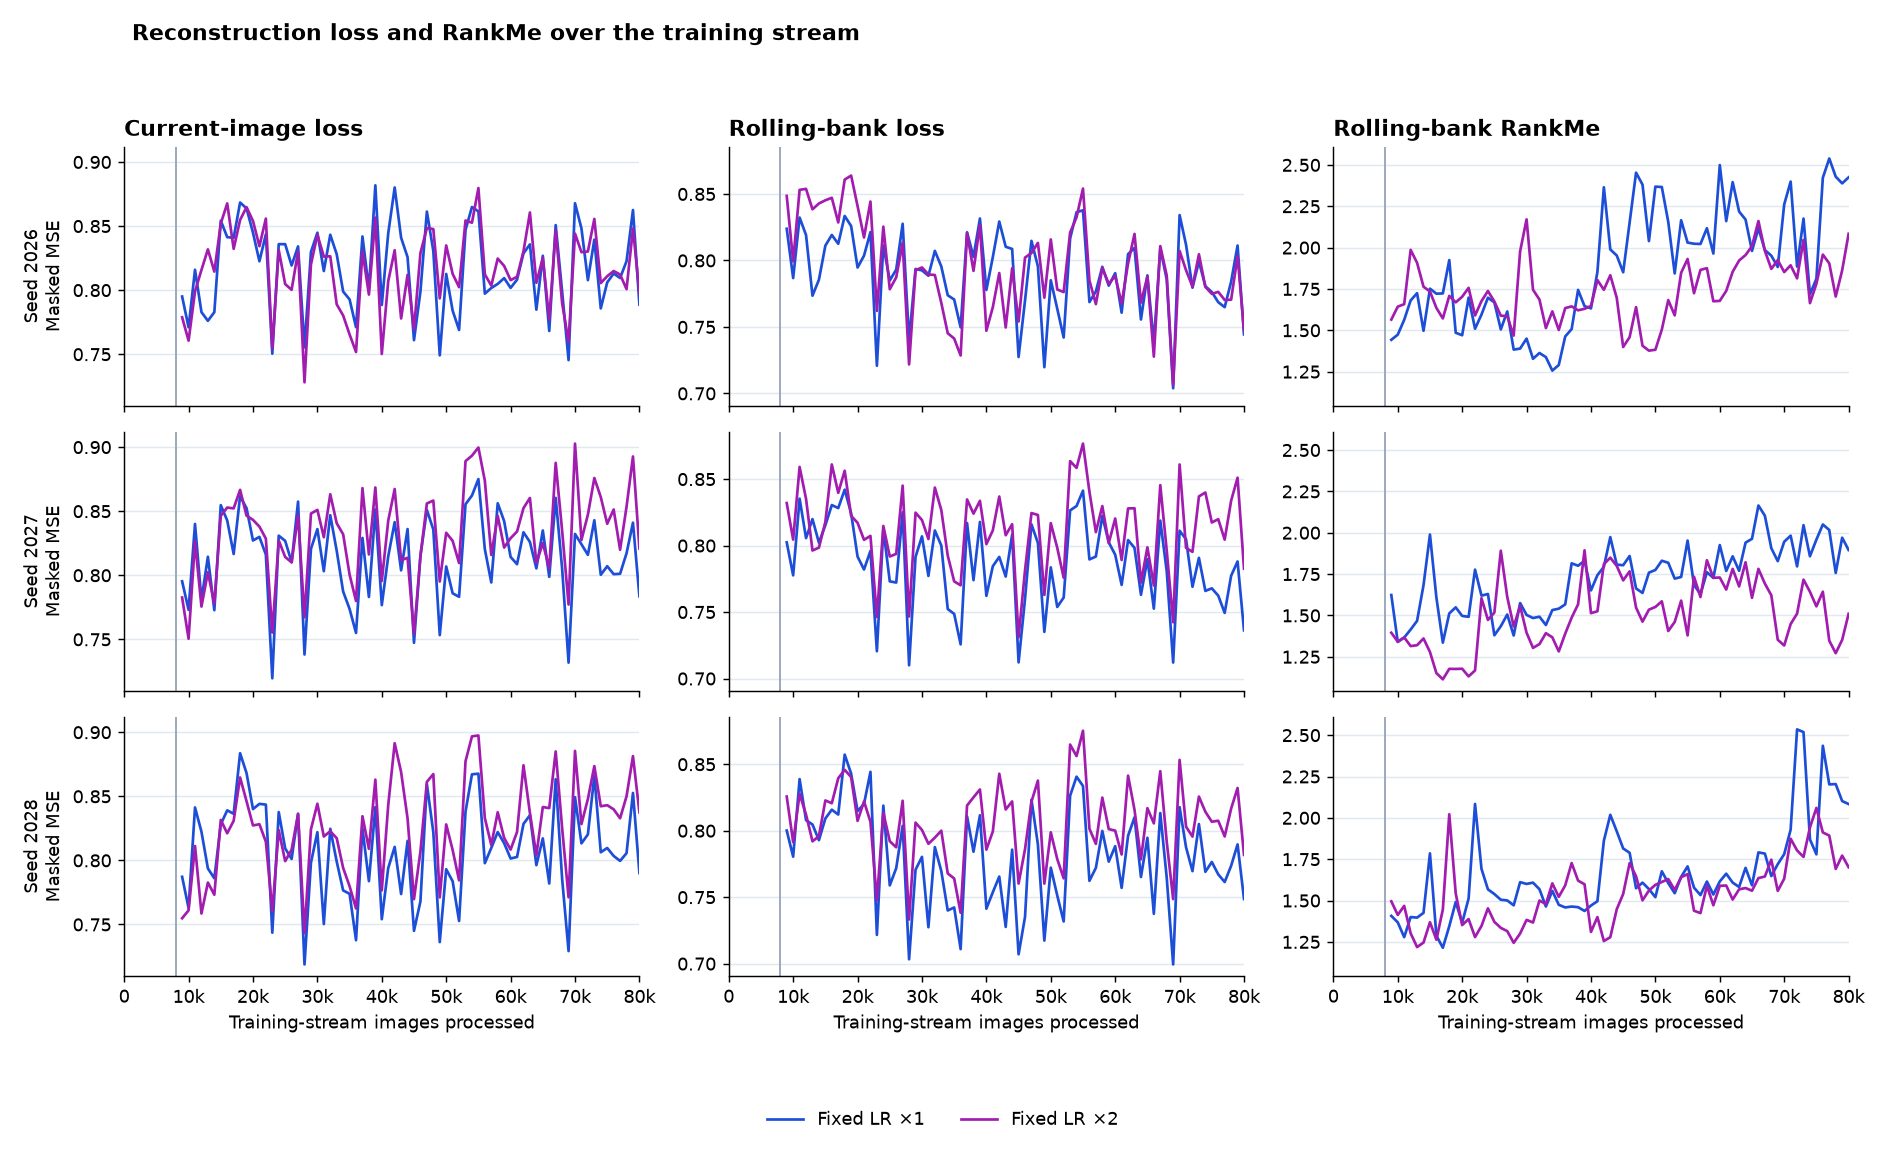

Run the watcher cell at the bottom for live plots while this notebook is open.

## Validation and held-out outcomes

| Split | Seed | LR | Reconstruction MSE | RankMe | Feature variance |
| --- | --- | --- | --- | --- | --- |
 | Validation | 2026 | 1× | 0.920855 | 5.66836 | 0.487803 | 
 | Validation | 2026 | 2× | 0.936909 | 3.76392 | 0.344332 | 
 | Validation | 2027 | 1× | 0.946005 | 3.308 | 0.578419 | 
 | Validation | 2027 | 2× | 1.01045 | 2.42039 | 0.0968028 | 
 | Validation | 2028 | 1× | 0.920035 | 3.78272 | 0.472316 | 
 | Validation | 2028 | 2× | 0.983917 | 2.39226 | 0.0829194 | 
 | Test | 2026 | 1× | 0.911347 | 5.70043 | 0.507549 | 
 | Test | 2026 | 2× | 0.926873 | 3.79336 | 0.324738 | 
 | Test | 2027 | 1× | 0.939468 | 3.28438 | 0.565587 | 
 | Test | 2027 | 2× | 1.01366 | 2.39223 | 0.0913212 | 
 | Test | 2028 | 1× | 0.905738 | 3.77695 | 0.470797 | 
 | Test | 2028 | 2× | 0.985318 | 2.39447 | 0.0765946 | 

In [ ]:
# Run this cell to watch the training curves. Interrupt it to stop watching.
from IPython.display import Image, clear_output, display
from pathlib import Path
import json, time

chart_path = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\fixed-2x\\training-curves.png')
status_path = chart_path.with_name('status.json')
while True:
    try:
        status = json.loads(status_path.read_text(encoding='utf-8'))
        png = chart_path.read_bytes()
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    display(Image(data=png))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)
